In [1]:

import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.datasets import make_circles

In [13]:

X, y = make_circles(n_samples=750,factor=0.5,noise=0.1)

In [14]:
X

array([[ 0.39128367, -0.10086144],
       [-0.48760874, -0.86335847],
       [-0.3625178 ,  0.13092169],
       ...,
       [ 0.46742739, -0.79957554],
       [-0.94682268, -0.20504436],
       [-0.60695792, -0.09991252]], shape=(750, 2))

In [15]:
y

array([1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0,
       0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1,
       0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0,
       1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0,

In [16]:
from sklearn.neighbors import LocalOutlierFactor

In [22]:
lc = LocalOutlierFactor(contamination = 0.1)

In [23]:
lc


,n_neighbors,20
,algorithm,'auto'
,leaf_size,30
,metric,'minkowski'
,p,2
,metric_params,None
,contamination,0.1
,novelty,False
,n_jobs,None


In [25]:
y_pred = lc.fit_predict(X)

In [27]:
n_errors = (y_pred != y).sum()
X_scores = lc.negative_outlier_factor_

In [28]:
n_errors


np.int64(431)

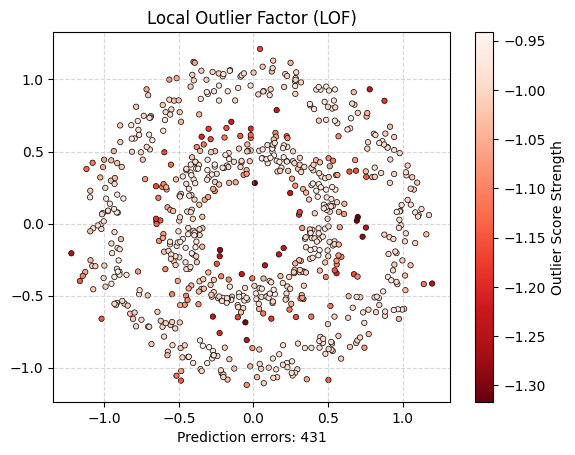

In [30]:
import matplotlib.pyplot as plt

scatter = plt.scatter(
    X[:, 0], 
    X[:, 1], 
    c=X_scores,           # Color points by outlier score
    cmap="Reds_r",        # Red for high outliers, lighter for normal points
    s=15,                 
    edgecolors="k", 
    linewidths=0.5
)

# 2. Add a simple colorbar instead of a messy legend
cbar = plt.colorbar(scatter)
cbar.set_label("Outlier Score Strength")

# 3. Minimalist styling
plt.title("Local Outlier Factor (LOF)")
plt.xlabel(f"Prediction errors: {n_errors}")
plt.axis("tight")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


### • -0.95 to -1.05 (Light Pink / White): These are the highest values on this plot. A score close to -1 means the point has a similar density to its neighbors. These are normal, inlier data points.

### • -1.20 to -1.30 (Dark Red / Maroon): These are the lowest values on this plot. Therefore, they are the most abnormal. These are your outliers.


### The darkest red points are scattered in the empty spaces (like the very center of the rings, the empty gap between the two rings, or completely outside the outer ring) where data is sparse. Because those dark points sit in low-density, unexpected areas, the algorithm correctly flags them as outliers and gives them the lowest (most negative) scores.

### 